<a href="https://colab.research.google.com/github/Revathisulochana/Python-Telecom-Customer-Churn-Analysis/blob/main/Python_Telecom_Customer_Churn_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Telecom Customer Churn Analysis Using Python

### Project overview
Customer churn occurs when customers stop using a company's services. Telecom companies need to understand why customers leave so they can improve customer satisfaction, retain existing customers, and reduce revenue loss.
This project analyzes telecom customer data to identify patterns and factors associated with churn.

### Data Source
• Dataset Name: Python Telecom Customer Churn Analysis

• Source: https://mavenanalytics.io/data-playground/telecom-customer-churn

- File Type: CSV

- Number of Records: 7,043 customer records.
- Number of Attributes: 38 columns.

The dataset contains customer demographic details, service subscriptions, contract information, billing and payment details, customer tenure, customer status, churn categories, and churn reasons. These attributes help analyze customer behavior and identify factors associated with telecom customer churn.

## Main Project Objectives:

To analyze telecom customer data, identify the major reasons for customer churn, understand customer behaviour, and provide business recommendations to improve customer retention.

### Specific objectives:

1. Calculate the overall customer churn rate.
2. Identify customer groups with higher churn rates.
3. Analyze the relationship between customer tenure and churn.
4. Understand how contract types influence customer churn.
5. Analyze the impact of monthly charges and total revenue on churn.
6. Identify the most common reasons for customers leaving.
7. Understand how internet services and additional services influence customer retention.
8. Provide recommendations to reduce customer churn and improve customer satisfaction.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# upload file from Google Drive
# Import Google Drive module
from google.colab import drive
drive.mount('/content/drive')

file_path = "/content/drive/MyDrive/Python coading/Raw dataset -Telecom_customer_churn.csv"

df = pd.read_csv(file_path)
print(df.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
  Customer ID  Gender  Age Married  Number of Dependents          City  \
0  0002-ORFBO  Female   37     Yes                     0  Frazier Park   
1  0003-MKNFE    Male   46      No                     0      Glendale   
2  0004-TLHLJ    Male   50      No                     0    Costa Mesa   
3  0011-IGKFF    Male   78     Yes                     0      Martinez   
4  0013-EXCHZ  Female   75     Yes                     0     Camarillo   

   Zip Code   Latitude   Longitude  Number of Referrals  ...   Payment Method  \
0     93225  34.827662 -118.999073                    2  ...      Credit Card   
1     91206  34.162515 -118.203869                    0  ...      Credit Card   
2     92627  33.645672 -117.922613                    0  ...  Bank Withdrawal   
3     94553  38.014457 -122.115432                    1  ...  Bank Withdrawal   
4     93010  34.22784

In [ ]:
# Number of rows and columns
print("Dataset Shape:", df.shape)

# Column names
print(df.columns)

# Data types and non-null values
df.info()

# Statistical summary
df.describe()

Dataset Shape: (7043, 38)
Index(['Customer ID', 'Gender', 'Age', 'Married', 'Number of Dependents',
       'City', 'Zip Code', 'Latitude', 'Longitude', 'Number of Referrals',
       'Tenure in Months', 'Offer', 'Phone Service',
       'Avg Monthly Long Distance Charges', 'Multiple Lines',
       'Internet Service', 'Internet Type', 'Avg Monthly GB Download',
       'Online Security', 'Online Backup', 'Device Protection Plan',
       'Premium Tech Support', 'Streaming TV', 'Streaming Movies',
       'Streaming Music', 'Unlimited Data', 'Contract', 'Paperless Billing',
       'Payment Method', 'Monthly Charge', 'Total Charges', 'Total Refunds',
       'Total Extra Data Charges', 'Total Long Distance Charges',
       'Total Revenue', 'Customer Status', 'Churn Category', 'Churn Reason'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 38 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------ 

,Age,Number of Dependents,Zip Code,Latitude,Longitude,Number of Referrals,Tenure in Months,Avg Monthly Long Distance Charges,Avg Monthly GB Download,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,6361.000000,5517.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,46.509726,0.468692,93486.070567,36.197455,-119.756684,1.951867,32.386767,25.420517,26.189958,63.596131,2280.381264,1.962182,6.860713,749.099262,3034.379056
std,16.750352,0.962802,1856.767505,2.468929,2.154425,3.001199,24.542061,14.200374,19.586585,31.204743,2266.220462,7.902614,25.104978,846.660055,2865.204542
min,19.000000,0.000000,90001.000000,32.555828,-124.301372,0.000000,1.000000,1.010000,2.000000,-10.000000,18.800000,0.000000,0.000000,0.000000,21.360000
25%,32.000000,0.000000,92101.000000,33.990646,-121.788090,0.000000,9.000000,13.050000,13.000000,30.400000,400.150000,0.000000,0.000000,70.545000,605.610000
50%,46.000000,0.000000,93518.000000,36.205465,-119.595293,0.000000,29.000000,25.690000,21.000000,70.050000,1394.550000,0.000000,0.000000,401.440000,2108.640000
75%,60.000000,0.000000,95329.000000,38.161321,-117.969795,3.000000,55.000000,37.680000,30.000000,89.750000,3786.600000,0.000000,0.000000,1191.100000,4801.145000
max,80.000000,9.000000,96150.000000,41.962127,-114.192901,11.000000,72.000000,49.990000,85.000000,118.750000,8684.800000,49.790000,150.000000,3564.720000,11979.340000


In [ ]:
# Count missing values
print(df.isnull().sum().sort_values(ascending=False))

Churn Reason                         5174
Churn Category                       5174
Offer                                3877
Online Backup                        1526
Avg Monthly GB Download              1526
Online Security                      1526
Streaming Movies                     1526
Streaming TV                         1526
Unlimited Data                       1526
Streaming Music                      1526
Internet Type                        1526
Device Protection Plan               1526
Premium Tech Support                 1526
Avg Monthly Long Distance Charges     682
Multiple Lines                        682
Number of Dependents                    0
City                                    0
Age                                     0
Gender                                  0
Customer ID                             0
Married                                 0
Tenure in Months                        0
Internet Service                        0
Longitude                         

In [ ]:
# Count each customer status
print(df["Customer Status"].value_counts())

# Calculate percentages
print((df["Customer Status"].value_counts(normalize=True) * 100).round(2))

Customer Status
Stayed     4720
Churned    1869
Joined      454
Name: count, dtype: int64
Customer Status
Stayed     67.02
Churned    26.54
Joined      6.45
Name: proportion, dtype: float64


### Data Cleaning

In [ ]:
df.isnull().sum()

,0
Customer ID,0
Gender,0
Age,0
Married,0
Number of Dependents,0
City,0
Zip Code,0
Latitude,0
Longitude,0
Number of Referrals,0


In [ ]:
#Check duplicate records
print("Duplicate Records:", df.duplicated().sum())


Duplicate Records: 0


In [ ]:
# Check invalid numerical values
print("Negative Monthly Charges:")
print((df['Monthly Charge'] < 0).sum())

Negative Monthly Charges:
120


In [ ]:
# Identify negative Monthly Charge records:
df[df['Monthly Charge'] < 0][
    ['Customer ID', 'Monthly Charge', 'Customer Status']
]

,Customer ID,Monthly Charge,Customer Status
1,0003-MKNFE,-4.0,Stayed
32,0052-DCKON,-2.0,Stayed
170,0274-JKUJR,-3.0,Stayed
232,0361-HJRDX,-8.0,Stayed
336,0495-ZBNGW,-1.0,Churned
...,...,...,...
6894,9793-WECQC,-1.0,Stayed
6918,9821-BESNZ,-7.0,Stayed
6976,9898-KZQDZ,-1.0,Churned
7020,9961-JBNMK,-1.0,Churned


In [ ]:
# Check customer status
print(df['Customer Status'].value_counts())

Customer Status
Stayed     4720
Churned    1869
Joined      454
Name: count, dtype: int64


### Data Transformation

In [ ]:
# Convert Customer ID into string
df['Customer ID'] = df['Customer ID'].astype(str)

In [ ]:
# Create a separate dataset for existing customers
analysis_df = df[
    df['Customer Status'].isin(['Stayed', 'Churned'])
].copy()

analysis_df.head()

,Customer ID,Gender,Age,Married,Number of Dependents,City,Zip Code,Latitude,Longitude,Number of Referrals,...,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Customer Status,Churn Category,Churn Reason
0,0002-ORFBO,Female,37,Yes,0,Frazier Park,93225,34.827662,-118.999073,2,...,Credit Card,65.6,593.30,0.00,0,381.51,974.81,Stayed,NaN,NaN
1,0003-MKNFE,Male,46,No,0,Glendale,91206,34.162515,-118.203869,0,...,Credit Card,-4.0,542.40,38.33,10,96.21,610.28,Stayed,NaN,NaN
2,0004-TLHLJ,Male,50,No,0,Costa Mesa,92627,33.645672,-117.922613,0,...,Bank Withdrawal,73.9,280.85,0.00,0,134.60,415.45,Churned,Competitor,Competitor had better devices
3,0011-IGKFF,Male,78,Yes,0,Martinez,94553,38.014457,-122.115432,1,...,Bank Withdrawal,98.0,1237.85,0.00,0,361.66,1599.51,Churned,Dissatisfaction,Product dissatisfaction
4,0013-EXCHZ,Female,75,Yes,0,Camarillo,93010,34.227846,-119.079903,3,...,Credit Card,83.9,267.40,0.00,0,22.14,289.54,Churned,Dissatisfaction,Network reliability


In [ ]:
# Create numerical churn status
analysis_df['Churn Flag'] = (
    analysis_df['Customer Status'] == 'Churned'
).astype(int)

In [ ]:
# Handle missing Offer values
df['Offer'] = df['Offer'].fillna('No Offer')

In [ ]:
# Prepare service-related columns

service_columns = [
    'Online Security',
    'Online Backup',
    'Device Protection Plan',
    'Premium Tech Support',
    'Streaming TV',
    'Streaming Movies',
    'Streaming Music'
]

for col in service_columns:
    print("\n", col)
    print(df[col].value_counts(dropna=False))


 Online Security
Online Security
No     3498
Yes    2019
NaN    1526
Name: count, dtype: int64

 Online Backup
Online Backup
No     3088
Yes    2429
NaN    1526
Name: count, dtype: int64

 Device Protection Plan
Device Protection Plan
No     3095
Yes    2422
NaN    1526
Name: count, dtype: int64

 Premium Tech Support
Premium Tech Support
No     3473
Yes    2044
NaN    1526
Name: count, dtype: int64

 Streaming TV
Streaming TV
No     2810
Yes    2707
NaN    1526
Name: count, dtype: int64

 Streaming Movies
Streaming Movies
No     2785
Yes    2732
NaN    1526
Name: count, dtype: int64

 Streaming Music
Streaming Music
No     3029
Yes    2488
NaN    1526
Name: count, dtype: int64


In [ ]:
# Check contract and payment categories

print("Contract Types:")
print(df['Contract'].value_counts())

print("\nPayment Methods:")
print(df['Payment Method'].value_counts())

Contract Types:
Contract
Month-to-Month    3610
Two Year          1883
One Year          1550
Name: count, dtype: int64

Payment Methods:
Payment Method
Bank Withdrawal    3909
Credit Card        2749
Mailed Check        385
Name: count, dtype: int64


### Feature Engineering

In [19]:
# Create Churn Flag

analysis_df['Churn Flag'] = (
    analysis_df['Customer Status'] == 'Churned'
).astype(int)

In [ ]:
# Create Tenure Groups

analysis_df['Tenure Group'] = pd.cut(
    analysis_df['Tenure in Months'],
    bins=[0, 12, 24, 48, 72],
    labels=[
        '0-12 Months',
        '13-24 Months',
        '25-48 Months',
        '49-72 Months'  ],
    include_lowest=True
)

In [ ]:
# Create Age Groups

analysis_df['Age Group'] = pd.cut(
    analysis_df['Age'],
    bins=[18, 25, 40, 60, 100],
    labels=['18-25 Years', '26-40 Years', '41-60 Years', 'Above 60 Years'
    ],
    include_lowest=True
)

In [ ]:
# Create Monthly Charge Category

analysis_df["Monthly Charge Category"] = pd.cut(
    analysis_df["Monthly Charge"],
    bins=[-float("inf"), 35, 70, float("inf")],
    labels=["Low", "Medium", "High"]
)

In [ ]:
# Additional Services Count

service_columns = [
    'Online Security',
    'Online Backup',
    'Device Protection Plan',
    'Premium Tech Support',
    'Streaming TV',
    'Streaming Movies',
    'Streaming Music'
]

analysis_df['Additional Services Count'] = (
    analysis_df[service_columns] == 'Yes'
).sum(axis=1)

In [ ]:
# Verify newly created columns

analysis_df[[
    "Churn Flag",
    "Tenure Group",
    "Age Group",
    "Monthly Charge Category",
    "Additional Services Count"
]].head(10)

,Churn Flag,Tenure Group,Age Group,Monthly Charge Category,Additional Services Count
0,0,0-12 Months,26-40 Years,Medium,3
1,0,0-12 Months,41-60 Years,Low,2
2,1,0-12 Months,41-60 Years,High,1
3,1,13-24 Months,Above 60 Years,High,4
4,1,0-12 Months,Above 60 Years,High,2
5,0,0-12 Months,18-25 Years,Medium,4
6,0,49-72 Months,Above 60 Years,High,7
7,0,49-72 Months,41-60 Years,High,2
8,0,0-12 Months,Above 60 Years,Medium,1
9,0,49-72 Months,41-60 Years,High,7


### Final Exploratory Data Analysis (EDA)

In [ ]:
# Overall Customer Churn Rate

total_customers = len(analysis_df)

churned_customers = analysis_df['Churn Flag'].sum()

churn_rate = (
    churned_customers / total_customers
) * 100

print("Total Existing Customers:", total_customers)
print("Churned Customers:", churned_customers)
print("Overall Churn Rate:", round(churn_rate, 2), "%")

Total Existing Customers: 6589
Churned Customers: 1869
Overall Churn Rate: 28.37 %


**Interpretation:** Approximately 28.37% of existing customers have discontinued their telecom services.

In [ ]:
# Customer Groups with Higher Churn Rates
group_columns = [
    'Gender',
    'Age Group',
    'Married'
]

for col in group_columns:

    print("\nChurn Rate by", col)

    result = (
        analysis_df.groupby(col, observed=False)['Churn Flag']
        .mean()
        .mul(100)
        .round(2)
    )

    print(result)


Churn Rate by Gender
Gender
Female    28.65
Male      28.08
Name: Churn Flag, dtype: float64

Churn Rate by Age Group
Age Group
18-25 Years       22.33
26-40 Years       25.99
41-60 Years       25.88
Above 60 Years    37.90
Name: Churn Flag, dtype: float64

Churn Rate by Married
Married
No     36.69
Yes    20.16
Name: Churn Flag, dtype: float64


**Interpretation:** This analysis helps identify customer groups with higher churn rates and supports targeted customer retention strategies.

In [ ]:
# Customer Tenure and Churn

tenure_analysis = (
    analysis_df.groupby('Tenure Group', observed=False)
    ['Churn Flag']
    .mean()
    .mul(100)
    .round(2)
)

print(tenure_analysis)

Tenure Group
0-12 Months     59.87
13-24 Months    28.71
25-48 Months    20.39
49-72 Months     9.51
Name: Churn Flag, dtype: float64


**Interpretation:** This analysis helps determine whether customers with shorter tenure are more likely to discontinue services compared with long-term customers.

In [ ]:
# Contract Type and Churn

contract_analysis = (
    analysis_df.groupby('Contract')['Churn Flag']
    .mean()
    .mul(100)
    .round(2)
)

print(contract_analysis)

Contract
Month-to-Month    51.69
One Year          10.88
Two Year           2.58
Name: Churn Flag, dtype: float64


**Interpretation**:This analysis compares churn rates across different contract types and identifies contract categories that require additional retention efforts.

In [ ]:
# Monthly Charges and Total Revenue

revenue_analysis = (
    analysis_df.groupby('Customer Status')[
        ['Monthly Charge', 'Total Revenue']
    ].agg(['mean', 'median'])
)

print(revenue_analysis)

                Monthly Charge        Total Revenue         
                          mean median          mean   median
Customer Status                                             
Churned              73.347592   79.5   1971.353569   893.55
Stayed               61.737415   65.6   3735.676297  2960.11


**Interpretation**: This analysis compares customer spending and revenue contribution between stayed and churned customers. It helps understand whether spending patterns are associated with churn.

In [ ]:
# Most Common Churn Reasons

churned_df = df[
    df['Customer Status'] == 'Churned'
].copy()

churn_reasons = churned_df['Churn Reason'].value_counts()

print(churn_reasons.head(10))

Churn Reason
Competitor had better devices                313
Competitor made better offer                 311
Attitude of support person                   220
Don't know                                   130
Competitor offered more data                 117
Competitor offered higher download speeds    100
Attitude of service provider                  94
Price too high                                78
Product dissatisfaction                       77
Network reliability                           72
Name: count, dtype: int64


**Interpretation**: This analysis identifies the most common reasons for customers leaving the company. It helps the business understand pricing, competitor offers, customer support and service dissatisfaction.

In [ ]:
# Internet Services and Customer Retention

internet_analysis = (
    analysis_df.groupby('Internet Type', dropna=False)
    ['Churn Flag']
    .agg(['mean', 'count'])
)

internet_analysis['Churn Rate (%)'] = (
    internet_analysis['mean'] * 100
).round(2)

print(internet_analysis)

                   mean  count  Churn Rate (%)
Internet Type                                 
Cable          0.275194    774           27.52
DSL            0.199740   1537           19.97
Fiber Optic    0.421268   2934           42.13
NaN            0.084077   1344            8.41


**Interpretation**: This analysis compares customer churn across internet service types and helps identify which service category requires improvement.

In [ ]:
# Additional Services and Customer Retention

service_analysis = (
    analysis_df.groupby('Additional Services Count')
    ['Churn Flag']
    .mean()
    .mul(100)
    .round(2)
)

print(service_analysis)

Additional Services Count
0    23.29
1    48.11
2    39.05
3    32.15
4    30.04
5    21.62
6    12.17
7     5.06
Name: Churn Flag, dtype: float64


## Statistical Analysis

In [ ]:
import pandas as pd
import numpy as np

analysis_df = df[
    df['Customer Status'].isin(['Stayed', 'Churned'])
].copy()

analysis_df['Churn Flag'] = (
    analysis_df['Customer Status'] == 'Churned'
).astype(int)

In [ ]:
stat_columns = [
    'Age',
    'Tenure in Months',
    'Monthly Charge',
    'Total Revenue',
    'Number of Referrals'
]

statistics = []

for col in stat_columns:

    data = analysis_df[col].dropna()

    statistics.append({
        'Variable': col,
        'Mean': data.mean(),
        'Median': data.median(),
        'Mode': data.mode().iloc[0],
        'Variance': data.var(),
        'Standard Deviation': data.std(),
        'Skewness': data.skew(),
        'Kurtosis': data.kurt()
    })

stats_df = pd.DataFrame(statistics)

print(stats_df.round(2))

              Variable     Mean   Median   Mode    Variance  \
0                  Age    46.76    46.00  47.00      283.63   
1     Tenure in Months    34.50    32.00   1.00      574.50   
2       Monthly Charge    65.03    71.05  20.05      967.26   
3        Total Revenue  3235.22  2376.45  24.80  8148741.37   
4  Number of Referrals     2.02     0.00   0.00        9.14   

   Standard Deviation  Skewness  Kurtosis  
0               16.84      0.15     -1.02  
1               23.97      0.16     -1.39  
2               31.10     -0.35     -1.06  
3             2854.60      0.86     -0.31  
4                3.02      1.40      0.58  


**Statistical interpretation**:

**Age**:
- Average customer age is approximately 47 years.
- Median age is 46 years.
- The customer age distribution is relatively balanced around its average.

**Tenure**:
- Average customer tenure is approximately 34.5 months.
- Median tenure is 32 months.
- The most frequently occurring tenure is 1 month.
- Customer tenure varies considerably.

**Monthly Charges**:
- Average monthly charge is approximately 65.03.
- Median monthly charge is 71.05.
- The mean is lower than the median, partly reflecting the negative values that require investigation.

**Total Revenue**:
- Average total revenue per existing customer is approximately 3,235.22.
- Median revenue is 2,376.45.
- The difference suggests that some customers contribute considerably higher revenue.

**Number of Referrals**:
- Average referrals per customer are approximately 2.
- Median and mode are both zero.
- Many customers have not referred other customers.

In [10]:
# Compare statistical measures by customer status

status_statistics = analysis_df.groupby(
    'Customer Status'
)[
    ['Tenure in Months',
     'Monthly Charge',
     'Total Revenue']
].agg([
    'mean',
    'median',
    'std'
])

print(status_statistics.round(2))


                Tenure in Months               Monthly Charge                \
                            mean median    std           mean median    std   
Customer Status                                                               
Churned                    17.98   10.0  19.53          73.35   79.5  26.37   
Stayed                     41.04   42.0  22.36          61.74   65.6  32.20   

                Total Revenue                    
                         mean   median      std  
Customer Status                                  
Churned               1971.35   893.55  2438.44  
Stayed                3735.68  2960.11  2852.94  


**Interpretation**:
- Churned customers have considerably shorter average tenure.
- Churned customers have higher average monthly charges.
- Stayed customers contribute higher average total revenue.
- Shorter tenure and higher monthly charges are useful areas for further investigation.

### Data Visualization

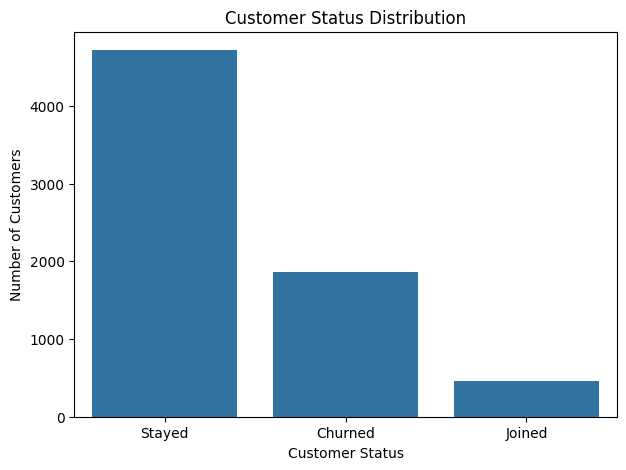

In [11]:
# Customer Status Distribution
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x='Customer Status',
    order=['Stayed', 'Churned', 'Joined']
)

plt.title('Customer Status Distribution')
plt.xlabel('Customer Status')
plt.ylabel('Number of Customers')

plt.show()

**Interpretation**:
- The chart displays three customer groups: Stayed, Churned and Joined.
- Stayed customers represent the largest group.
- There are 1,869 churned customers.
- This chart provides an overview of customer retention and churn.

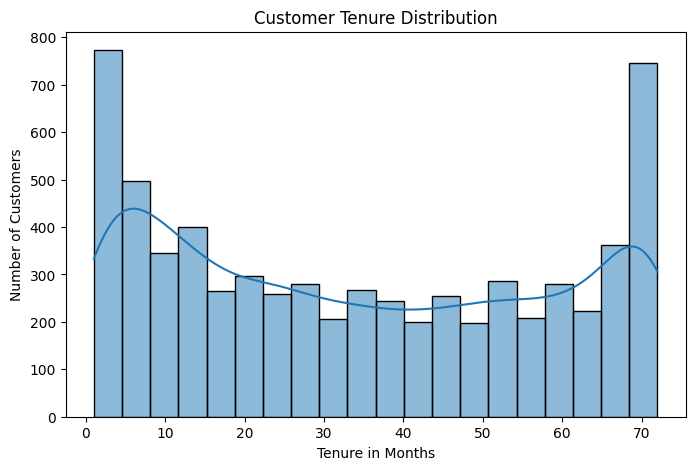

In [12]:
# Customer Tenure Distribution

plt.figure(figsize=(8,5))

sns.histplot(
    data=analysis_df,
    x='Tenure in Months',
    bins=20,
    kde=True
)

plt.title('Customer Tenure Distribution')
plt.xlabel('Tenure in Months')
plt.ylabel('Number of Customers')

plt.show()

**Interpretation**:
- The histogram shows the distribution of customer tenure.
- It helps identify how long customers have been using telecom services.
- The distribution shows variation in customer tenure.
- This analysis supports customer loyalty investigation.

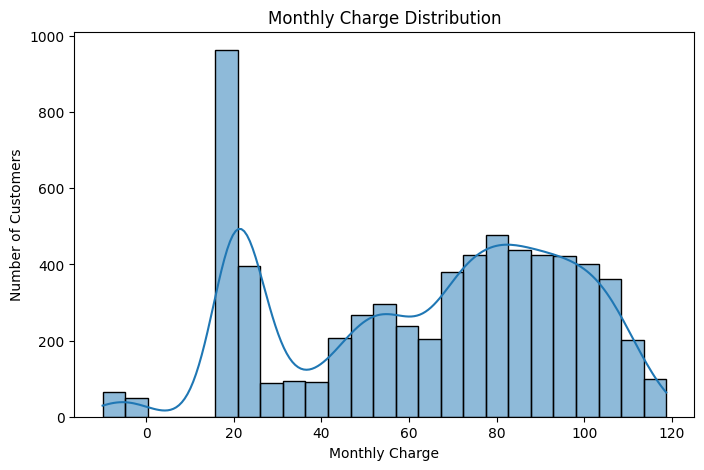

In [13]:
# Monthly Charge Distribution

plt.figure(figsize=(8,5))

sns.histplot(
    data=analysis_df,
    x='Monthly Charge',
    bins=25,
    kde=True
)

plt.title('Monthly Charge Distribution')
plt.xlabel('Monthly Charge')
plt.ylabel('Number of Customers')

plt.show()

**Interpretation**:
- The chart displays customer monthly charge distribution.
- It helps identify common spending ranges.
- Unusual negative values are present and should be investigated.
- Monthly charge patterns can help understand customer spending behaviour.

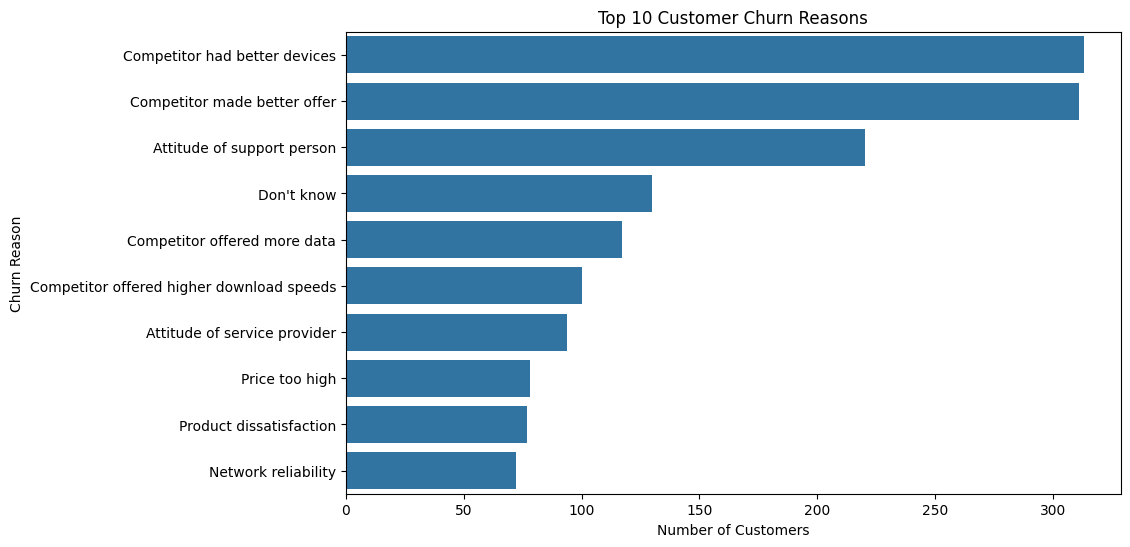

In [14]:
# Most Common Churn Reasons
churned_df = df[
    df['Customer Status'] == 'Churned'
].copy()

plt.figure(figsize=(10,6))

sns.countplot(
    data=churned_df,
    y='Churn Reason',
    order=churned_df['Churn Reason'].value_counts().head(10).index
)

plt.title('Top 10 Customer Churn Reasons')
plt.xlabel('Number of Customers')
plt.ylabel('Churn Reason')

plt.show()

**Interpretation**:
- Competitor-related reasons are among the most frequently reported causes of churn.
- Better devices and better offers from competitors are major concerns.
- Customer support attitude is another important reason.
- The company should improve competitive offers and customer service.

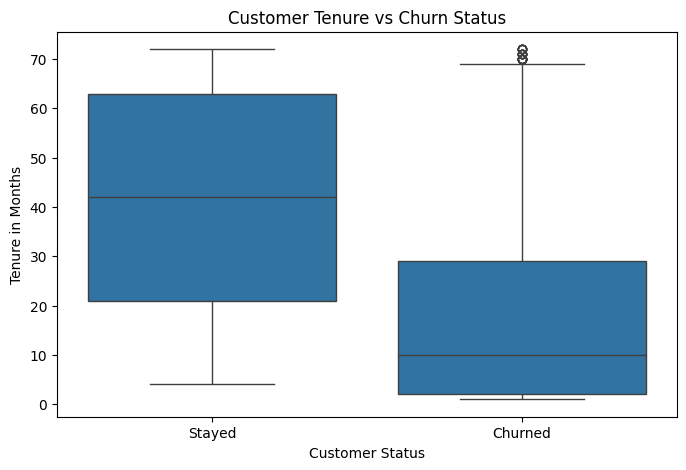

In [15]:
# Tenure vs Customer Churn
plt.figure(figsize=(8,5))

sns.boxplot(
    data=analysis_df,
    x='Customer Status',
    y='Tenure in Months'
)

plt.title('Customer Tenure vs Churn Status')
plt.xlabel('Customer Status')
plt.ylabel('Tenure in Months')

plt.show()

**Interpretation**:
- The chart compares customer tenure between stayed and churned customers.
- Churned customers have a lower median tenure than stayed customers.
- This indicates that customers with shorter service periods are more likely to leave.
- The company should focus on improving customer engagement during the initial months.

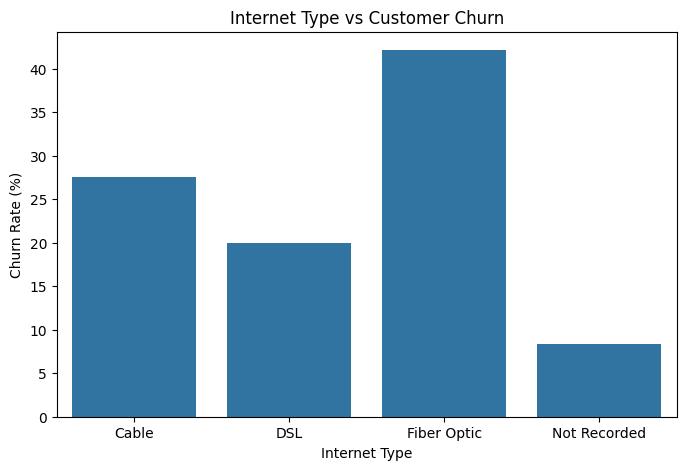

In [20]:
# Internet Type vs Churn Rate
internet_churn = (
    analysis_df.groupby('Internet Type', dropna=False)
    ['Churn Flag']
    .mean()
    .mul(100)
    .reset_index()
)

internet_churn['Internet Type'] = (
    internet_churn['Internet Type'].fillna('Not Recorded')
)

plt.figure(figsize=(8,5))

sns.barplot(
    data=internet_churn,
    x='Internet Type',
    y='Churn Flag'
)

plt.title('Internet Type vs Customer Churn')
plt.xlabel('Internet Type')
plt.ylabel('Churn Rate (%)')

plt.show()

**Interpretation**:
- Fiber Optic customers have a churn rate of approximately 42.13%.
- Cable customers have a churn rate of approximately 27.52%.
- DSL customers have a churn rate of approximately 19.97%.
- Fiber Optic customers require further investigation to understand service quality, pricing and customer satisfaction.

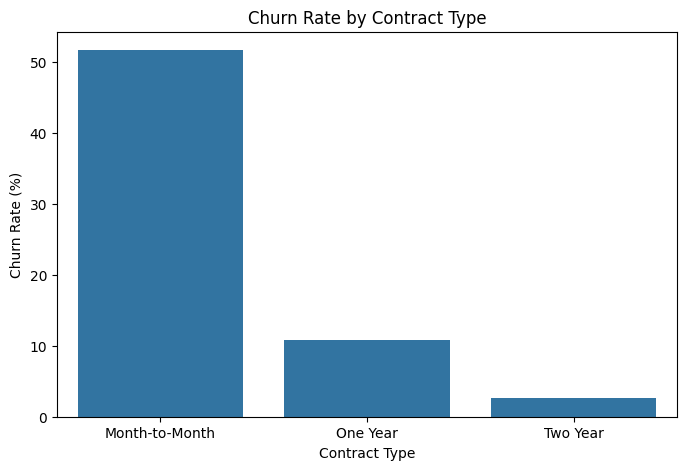

In [21]:
# Contract Type vs Churn Rate
contract_churn = (
    analysis_df.groupby('Contract')['Churn Flag']
    .mean()
    .mul(100)
    .reset_index()
)

plt.figure(figsize=(8,5))

sns.barplot(
    data=contract_churn,
    x='Contract',
    y='Churn Flag'
)

plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')

plt.show()

**Interpretation**:
- Month-to-Month customers have the highest churn rate at approximately 51.69%.
- One Year contract customers have a churn rate of approximately 10.88%.
- Two Year contract customers have the lowest churn rate at approximately 2.58%.
- Longer contract commitments are associated with lower customer churn.

In [24]:
# Additional Services vs Customer Churn

service_columns = [
    'Online Security',
    'Online Backup',
    'Device Protection Plan',
    'Premium Tech Support',
    'Streaming TV',
    'Streaming Movies',
    'Streaming Music'
]

analysis_df['Additional Services Count'] = (
    analysis_df[service_columns] == 'Yes'
).sum(axis=1)

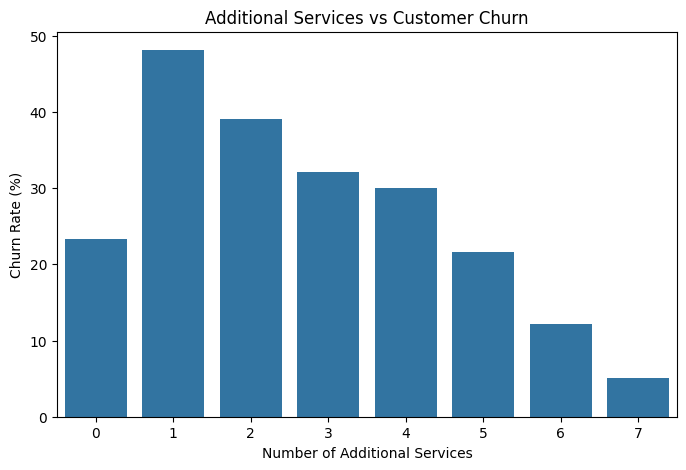

In [25]:
service_churn = (
    analysis_df.groupby('Additional Services Count')
    ['Churn Flag']
    .mean()
    .mul(100)
    .reset_index()
)

plt.figure(figsize=(8,5))

sns.barplot(
    data=service_churn,
    x='Additional Services Count',
    y='Churn Flag'
)

plt.title('Additional Services vs Customer Churn')
plt.xlabel('Number of Additional Services')
plt.ylabel('Churn Rate (%)')

plt.show()

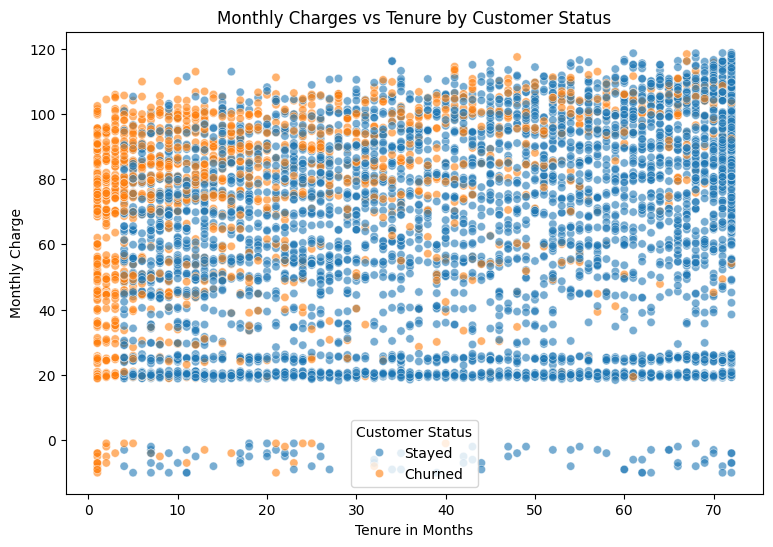

In [26]:
# Monthly Charges vs Tenure by Customer Status
plt.figure(figsize=(9,6))

sns.scatterplot(
    data=analysis_df,
    x='Tenure in Months',
    y='Monthly Charge',
    hue='Customer Status',
    alpha=0.6
)

plt.title('Monthly Charges vs Tenure by Customer Status')
plt.xlabel('Tenure in Months')
plt.ylabel('Monthly Charge')

plt.show()

**Interpretation**:
- This chart examines monthly charges and customer tenure together.
- It differentiates stayed and churned customers.
- It helps identify whether customers with shorter tenure and higher monthly charges are concentrated among churned customers.
- The company can use these observations to improve pricing and customer retention strategies.

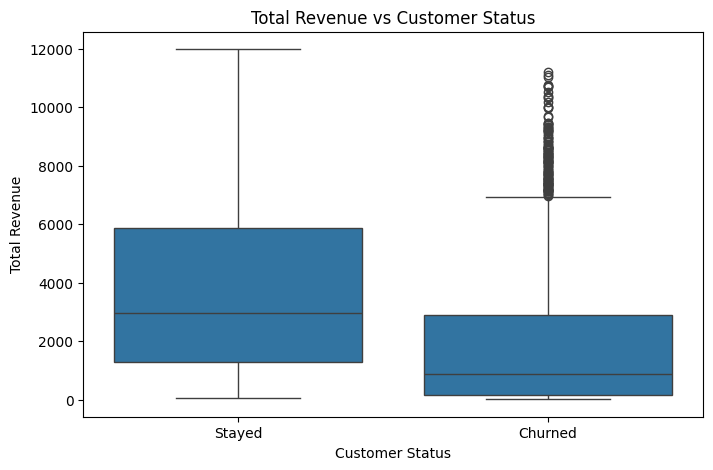

In [27]:
# Total Revenue vs Customer Status

plt.figure(figsize=(8,5))

sns.boxplot(
    data=analysis_df,
    x='Customer Status',
    y='Total Revenue'
)

plt.title('Total Revenue vs Customer Status')
plt.xlabel('Customer Status')
plt.ylabel('Total Revenue')

plt.show()

**Interpretation**:
- The chart compares total revenue generated by stayed and churned customers.
- Stayed customers have higher average total revenue (3,735.68) than churned customers (1,971.35).
- This indicates that retained customers contribute more revenue on average.
- The company should focus on retaining valuable customers and improving customer loyalty.